# Step 1: Data Loading & Feature Engineering

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing

In [27]:
california = fetch_california_housing(as_frame=True)
df = california.frame

df['Rooms_per_Household'] = df['AveRooms'] / df['AveOccup']
df['Bedrooms_per_Room'] = df['AveBedrms'] / df['AveRooms']

X = df.drop(columns=['MedHouseVal'])
y = df["MedHouseVal"]

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,Rooms_per_Household,Bedrooms_per_Room
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526,2.732919,0.146591
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585,2.956685,0.155797
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521,2.957661,0.129516
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413,2.283154,0.184458
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422,2.879646,0.172096


# Step 2: Imputation, Encoding, and Correlation Heatmap

In [28]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [29]:
num_cols = X.select_dtypes(include=['float64', 'int64']).columns
imputer = SimpleImputer(strategy='median')
X_num_imputed = pd.DataFrame(imputer.fit_transform(X[num_cols]), columns=num_cols)

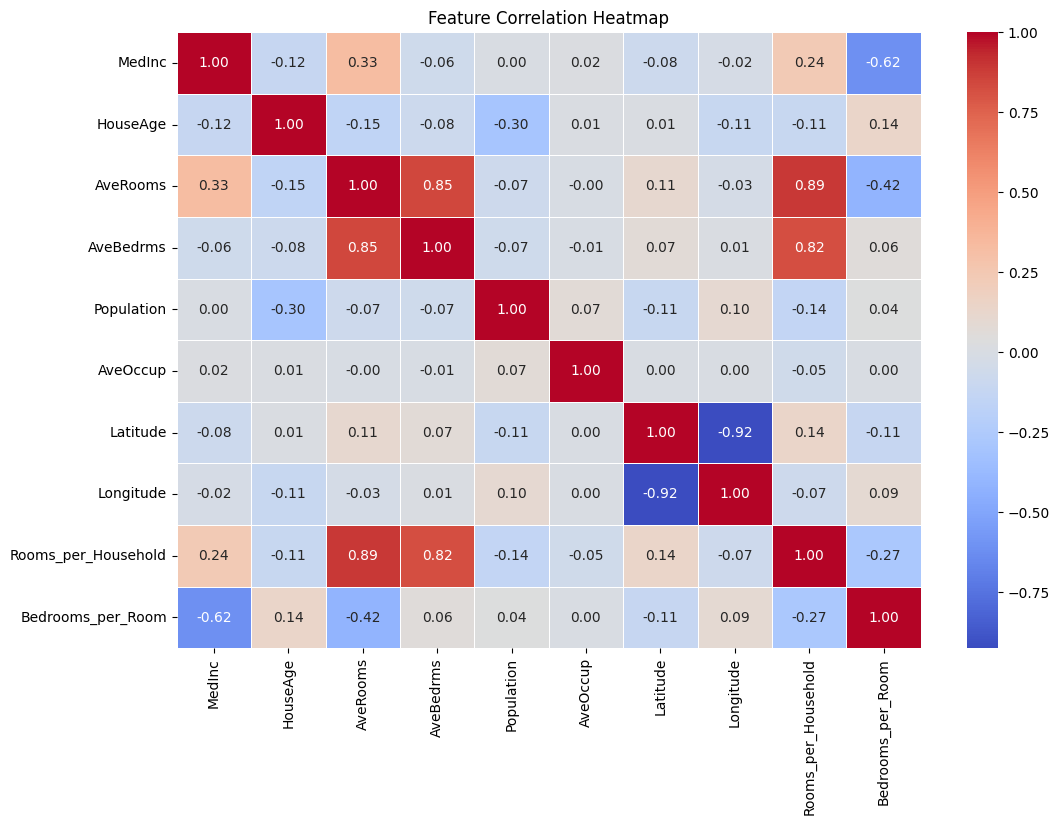

In [30]:
plt.figure(figsize=(12, 8))
sns.heatmap(X_num_imputed.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Feature Correlation Heatmap")
plt.show()

In [31]:
cat_cols = X.select_dtypes(include=['object', 'category']).columns

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ])

# Step 3: Model Training with GridSearchCV

In [32]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [33]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

ols_pipeline = Pipeline([('preprocessor', preprocessor), ('model', LinearRegression())])
ols_pipeline.fit(X_train, y_train)
ols_preds = ols_pipeline.predict(X_test)

In [34]:
ridge_pipeline = Pipeline([('preprocessor', preprocessor), ('model', Ridge())])
ridge_params = {'model__alpha': [0.1, 1.0, 10.0, 100.0]}
ridge_grid = GridSearchCV(ridge_pipeline, ridge_params, cv=5, scoring='neg_mean_squared_error')
ridge_grid.fit(X_train, y_train)
ridge_preds = ridge_grid.predict(X_test)

In [35]:
lasso_pipeline = Pipeline([('preprocessor', preprocessor), ('model', Lasso())])
lasso_params = {'model__alpha': [0.001, 0.01, 0.1, 1.0]}
lasso_grid = GridSearchCV(lasso_pipeline, lasso_params, cv=5, scoring='neg_mean_squared_error')
lasso_grid.fit(X_train, y_train)
lasso_preds = lasso_grid.predict(X_test)
print(f"Best Ridge Alpha: {ridge_grid.best_params_['model__alpha']}")
print(f"Best Lasso Alpha: {lasso_grid.best_params_['model__alpha']}")

Best Ridge Alpha: 10.0
Best Lasso Alpha: 0.001


# Step 4: Metric Comparison & Residual Error Analysis

In [36]:
def evaluate_model(name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"--- {name} ---")
    print(f"RMSE: {rmse:.4f} | MAE: {mae:.4f} | R²: {r2:.4f}\n")
    return y_pred

print("MODEL COMPARISON")
evaluate_model("OLS Linear Regression", y_test, ols_preds)
evaluate_model("Ridge Regression", y_test, ridge_preds)
evaluate_model("Lasso Regression", y_test, lasso_preds)

MODEL COMPARISON
--- OLS Linear Regression ---
RMSE: 0.6753 | MAE: 0.4862 | R²: 0.6519

--- Ridge Regression ---
RMSE: 0.6754 | MAE: 0.4862 | R²: 0.6519

--- Lasso Regression ---
RMSE: 0.6757 | MAE: 0.4863 | R²: 0.6516



array([0.54820673, 1.71427694, 3.25582367, ..., 4.49736304, 1.28294311,
       1.80622901], shape=(4128,))

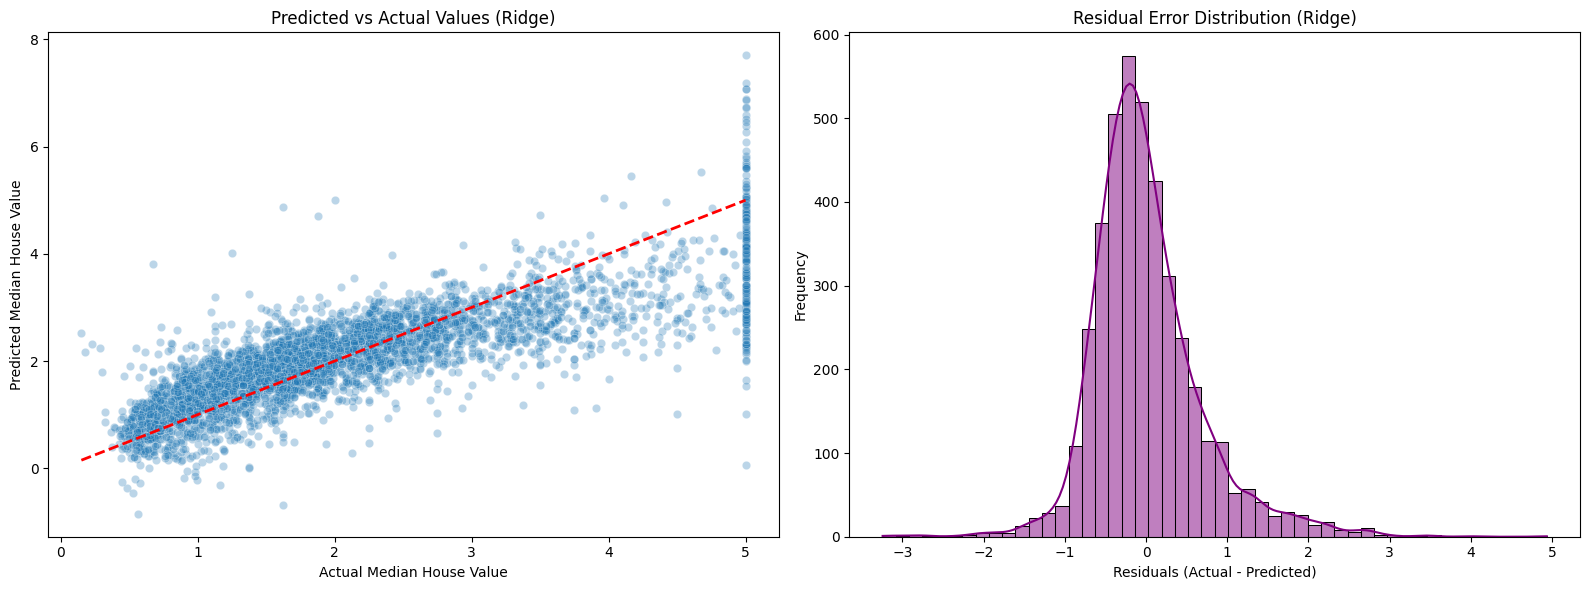

In [38]:
residuals = y_test - ridge_preds

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Predicted vs Actual Values
sns.scatterplot(x=y_test, y=ridge_preds, alpha=0.3, ax=axes[0])
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_title('Predicted vs Actual Values (Ridge)')
axes[0].set_xlabel('Actual Median House Value')
axes[0].set_ylabel('Predicted Median House Value')
sns.histplot(residuals, kde=True, bins=50, ax=axes[1], color='purple')
axes[1].set_title('Residual Error Distribution (Ridge)')
axes[1].set_xlabel('Residuals (Actual - Predicted)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()